Found 56 nodes and 74 edges.


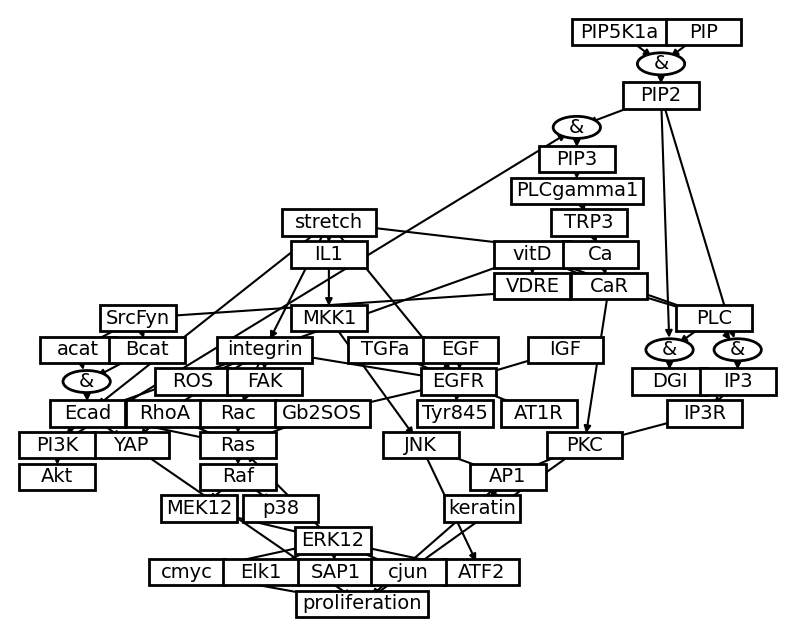

In [27]:
import networkx as nx
import matplotlib.pyplot as plt
import pygraphviz as pgv
from lxml import etree
from networkx.drawing.nx_agraph import graphviz_layout
import matplotlib.patches as mpatches

def load_xgmml(file_path):
    tree = etree.parse(file_path)
    root = tree.getroot()

    ns = {"xgmml": root.nsmap[None]}  # Correct namespace

    G = nx.DiGraph()  # Directed graph to enforce hierarchy

    nodes = root.findall(".//xgmml:node", namespaces=ns)
    edges = root.findall(".//xgmml:edge", namespaces=ns)

    print(f"Found {len(nodes)} nodes and {len(edges)} edges.")

    for node in nodes:
        node_id = node.get("id")
        node_label = node.get("label", node_id)

        # Modify label for nodes starting with "rcn..."
        if node_label.startswith("rcn"):
            node_label = "&"

        G.add_node(node_id, label=node_label)

    for edge in edges:
        source = edge.get("source")
        target = edge.get("target")
        G.add_edge(source, target)

    return G

# Load the network
G = load_xgmml("NetworkKeratinocyteTINYwStyle.xgmml")

# ✅ Use `dot` for hierarchical layout
pos = graphviz_layout(G, prog="dot")  

# Extract labels from node attributes
labels = {node: data["label"] for node, data in G.nodes(data=True)}

# Create figure
fig, ax = plt.subplots(figsize=(10, 8))

# Draw edges
nx.draw_networkx_edges(G, pos, ax=ax, edge_color="black", width=1.5, arrows=True)

# ✅ Adjust font size for labels
nx.draw_networkx_labels(G, pos, labels, font_size=14, font_color="black")  

# ✅ Draw nodes as **rectangles or circles**
default_rect_width = 80  # Standard width for most nodes
default_rect_height = 60  # Standard height for all rectangles
circle_radius = 25  # Adjust size for circles

# Define special widths for long-named nodes
long_node_widths = {
    "proliferation": 140,  # Wider than normal
    "PLCgamma1": 140,       # Wider than normal
    "stretch": 100,       # Slightly wider than normal
    "PIP5K1a": 100,       # Slightly wider than normal
    "Gb2SOS": 100,       # Slightly wider than normal
    "integrin": 100       # Slightly wider than normal
}

for node, (x, y) in pos.items():
    node_label = labels[node]

    if node_label == "&":  # If it's an "rcn..." node, draw a circle
        circle = mpatches.Circle((x, y), circle_radius, facecolor="white", edgecolor="black", lw=2)
        ax.add_patch(circle)
    else:  # Draw a rectangle for all other nodes
        rect_width = long_node_widths.get(node_label, default_rect_width)  # Adjust width for long nodes
        rectangle = mpatches.Rectangle((x - rect_width / 2, y - default_rect_height / 2), 
                                       rect_width, default_rect_height, 
                                       facecolor="white", edgecolor="black", lw=2)
        ax.add_patch(rectangle)

# Adjust plot limits to fit both circles and rectangles
ax.set_xlim(min(x for x, y in pos.values()) - 50, max(x for x, y in pos.values()) + 50)
ax.set_ylim(min(y for x, y in pos.values()) - 50, max(y for x, y in pos.values()) + 50)

ax.set_xticks([])  # Remove x-axis ticks
ax.set_yticks([])  # Remove y-axis ticks
ax.set_frame_on(False)  # Hide axis frame

plt.savefig('KeratinocyteNetworkSmall_1.png', dpi=300, bbox_inches='tight')


plt.show()


Found 128 nodes and 219 edges.


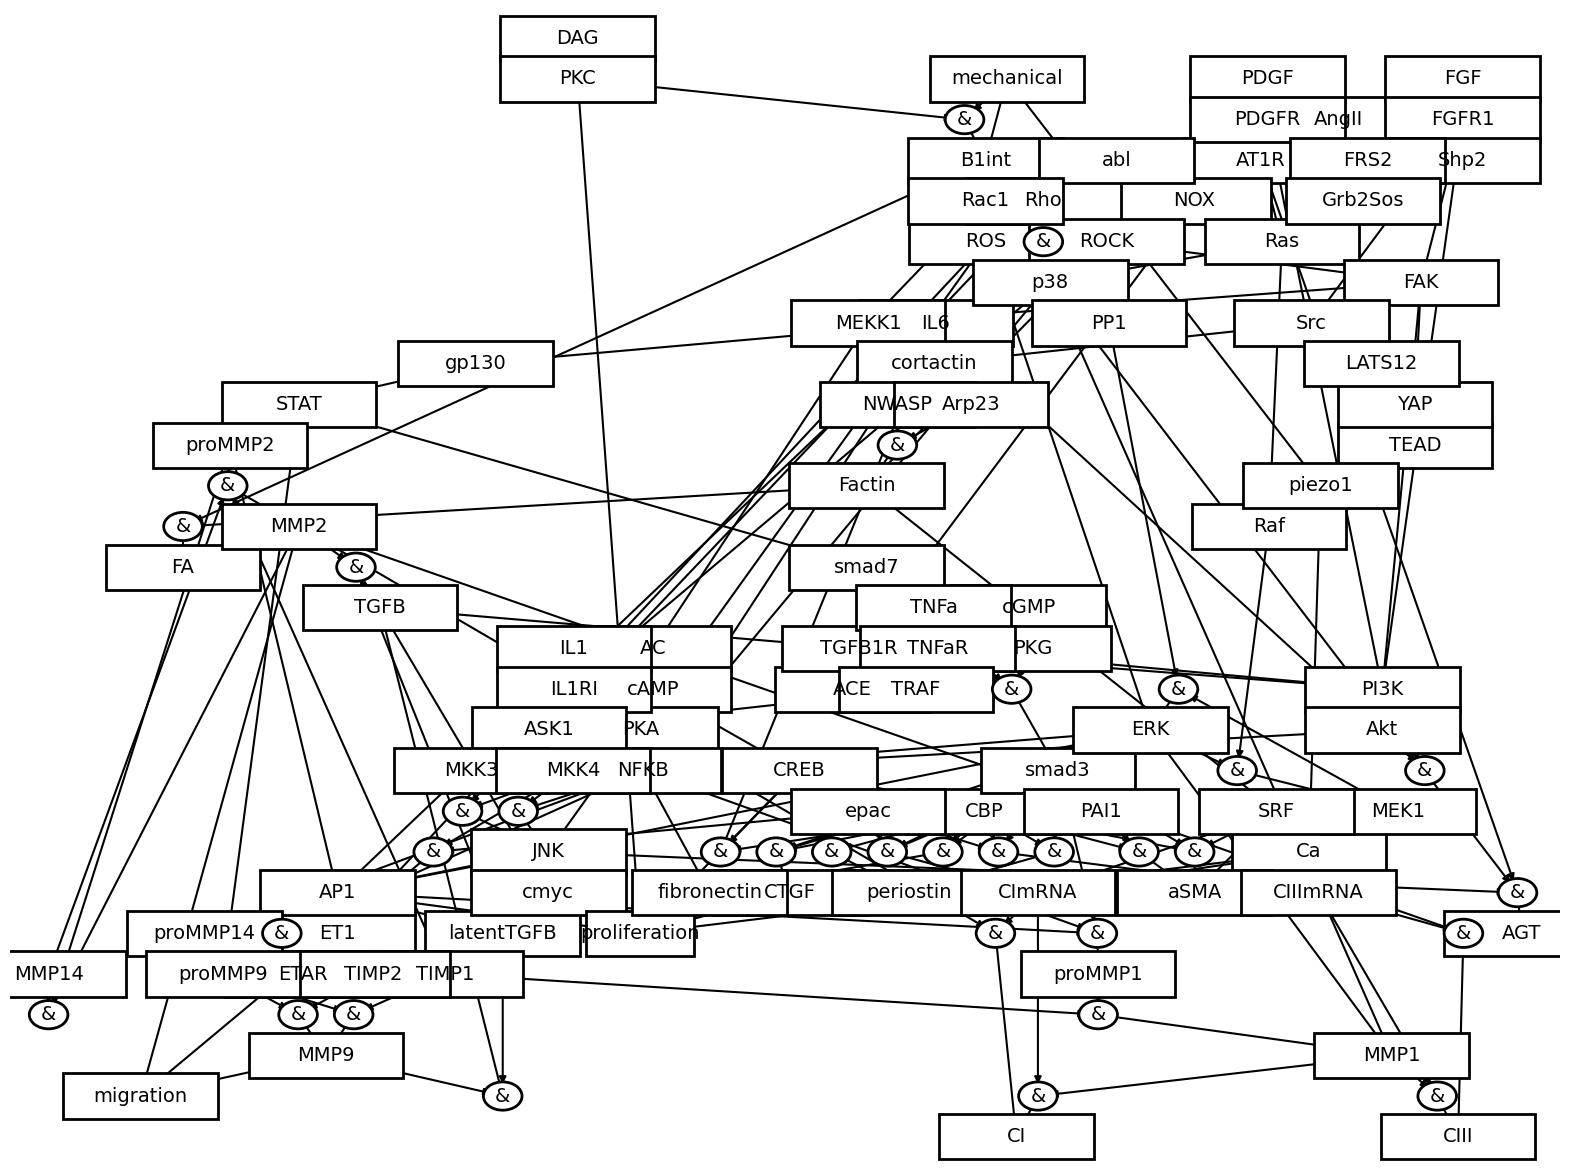

In [32]:
import networkx as nx
import matplotlib.pyplot as plt
import pygraphviz as pgv
from lxml import etree
from networkx.drawing.nx_agraph import graphviz_layout
import matplotlib.patches as mpatches

def load_xgmml(file_path):
    tree = etree.parse(file_path)
    root = tree.getroot()

    ns = {"xgmml": root.nsmap[None]}  # Correct namespace

    G = nx.DiGraph()  # Directed graph to enforce hierarchy

    nodes = root.findall(".//xgmml:node", namespaces=ns)
    edges = root.findall(".//xgmml:edge", namespaces=ns)

    print(f"Found {len(nodes)} nodes and {len(edges)} edges.")

    for node in nodes:
        node_id = node.get("id")
        node_label = node.get("label", node_id)

        # Modify label for nodes starting with "rcn..."
        if node_label.startswith("rcn"):
            node_label = "&"

        G.add_node(node_id, label=node_label)

    for edge in edges:
        source = edge.get("source")
        target = edge.get("target")
        G.add_edge(source, target)

    return G

# Load the network
G = load_xgmml("NetworkFibroblastTINYwStyle.xgmml")

# ✅ Use `dot` for hierarchical layout
pos = graphviz_layout(G, prog="dot")  

# Extract labels from node attributes
labels = {node: data["label"] for node, data in G.nodes(data=True)}

# Create figure
fig, ax = plt.subplots(figsize=(20, 15))

# Draw edges
nx.draw_networkx_edges(G, pos, ax=ax, edge_color="black", width=1.5, arrows=True)

# ✅ Adjust font size for labels
nx.draw_networkx_labels(G, pos, labels, font_size=14, font_color="black")  

# ✅ Draw nodes as **rectangles or circles**
default_rect_width = 200  # Standard width for most nodes
default_rect_height = 80  # Standard height for all rectangles
circle_radius = 25  # Adjust size for circles

# Define special widths for long-named nodes
long_node_widths = {
    "proliferation": 140,  # Wider than normal
    "PLCgamma1": 140,       # Wider than normal
    "stretch": 100,       # Slightly wider than normal
    "PIP5K1a": 100,       # Slightly wider than normal
    "Gb2SOS": 100,       # Slightly wider than normal
    "integrin": 100       # Slightly wider than normal
}

for node, (x, y) in pos.items():
    node_label = labels[node]

    if node_label == "&":  # If it's an "rcn..." node, draw a circle
        circle = mpatches.Circle((x, y), circle_radius, facecolor="white", edgecolor="black", lw=2)
        ax.add_patch(circle)
    else:  # Draw a rectangle for all other nodes
        rect_width = long_node_widths.get(node_label, default_rect_width)  # Adjust width for long nodes
        rectangle = mpatches.Rectangle((x - rect_width / 2, y - default_rect_height / 2), 
                                       rect_width, default_rect_height, 
                                       facecolor="white", edgecolor="black", lw=2)
        ax.add_patch(rectangle)

# Adjust plot limits to fit both circles and rectangles
ax.set_xlim(min(x for x, y in pos.values()) - 50, max(x for x, y in pos.values()) + 50)
ax.set_ylim(min(y for x, y in pos.values()) - 50, max(y for x, y in pos.values()) + 50)

ax.set_xticks([])  # Remove x-axis ticks
ax.set_yticks([])  # Remove y-axis ticks
ax.set_frame_on(False)  # Hide axis frame

plt.savefig('FibroblastNetworkSmall_1.png', dpi=300, bbox_inches='tight')


plt.show()